# Etapa 6 v2 — resumo da calibração e achados até o momento

Reproduz os dois gráficos gerados na sessão de 2026-07-16 a partir do lote completo (1000 imagens)
da etapa 6 v2 (âncora pela aorta), e reúne um resumo textual dos achados de todo o percurso da
etapa 6 no Capítulo 2 — desde a 1ª tentativa (âncora pelo LCC, descartada) até o resultado atual
(âncora pela aorta, calibrada, mas com cobertura <100% e `Rv` baixo).

Não reprocessa nada pesado — só lê os resultados já salvos em
`output/bounding_box/aorta_anchor/` (produzidos por
`uv run python src/run_aorta_anchor.py --splits config/imagecas_splits_train90.json`, ~10h de
execução) e reaproveita as funções de plot de
[plot_aorta_anchor_extremes.py](plot_aorta_anchor_extremes.py), para não duplicar o código dos
gráficos entre script e notebook.

Ver [docs/step6v2_aorta_anchor.md](../../docs/step6v2_aorta_anchor.md) para a documentação
completa (racional da âncora pela aorta, achado sobre o LCC, achado sobre GPU, achado sobre o
`Rv`).

In [1]:
# ruff: noqa: E402

import sys
from pathlib import Path

NOTEBOOK_CWD = Path.cwd().resolve()
for candidate in (
    NOTEBOOK_CWD,
    NOTEBOOK_CWD.parent,
    NOTEBOOK_CWD.parent.parent,
):
    src_dir = candidate / "src"
    if src_dir.exists():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break

from utils.project.notebook_env import configure_notebook_environment  # noqa: E402

REPO_ROOT = configure_notebook_environment()
print(f"REPO_ROOT = {REPO_ROOT}")


REPO_ROOT = G:\DAC\heart-bounding-box


In [2]:
import json
import random

import numpy as np
import pandas as pd

from eda.plot_aorta_anchor_extremes import (
    COVERAGE_LEVELS,
    DOCS_IMG_DIR,
    OUTPUT_DIR,
    SPLITS_STEM,
    compute_coverage_percentiles,
    plot_offset_histograms,
    plot_worst_coverage_cases,
)
from utils.utils.nifti_io import load_raw_img_and_label

if not OUTPUT_DIR.exists():
    raise FileNotFoundError(
        f"{OUTPUT_DIR} não encontrado — rode primeiro "
        "`uv run python src/run_aorta_anchor.py --splits config/imagecas_splits_train90.json` "
        "(demora ~10h; os resultados já ficam salvos incrementalmente)."
    )


## 1. Carregar os resultados do lote (994/1000 casos, calibração com split `train90`)

In [3]:
all_cases = pd.read_csv(OUTPUT_DIR / "all_cases.csv")
ok = all_cases[all_cases["status"] == "ok"].copy()
for axis in ("y", "x", "z"):
    ok[f"offset_min_{axis}"] = ok[f"label_{axis}_min"] - ok[f"anchor_{axis}"]
    ok[f"offset_max_{axis}"] = ok[f"label_{axis}_max"] - ok[f"anchor_{axis}"]

calibration = json.loads((OUTPUT_DIR / f"calibration_{SPLITS_STEM}.json").read_text(encoding="utf-8"))
splits = json.loads((REPO_ROOT / "config" / f"{SPLITS_STEM}.json").read_text(encoding="utf-8"))["splits"]
train_ids = {int(img_id) for img_id in splits["train"]}

val = pd.read_csv(OUTPUT_DIR / f"coverage_val_{SPLITS_STEM}.csv")
test = pd.read_csv(OUTPUT_DIR / f"coverage_test_{SPLITS_STEM}.csv")
val["split"] = "val"
test["split"] = "test"
coverage = pd.concat([val, test], ignore_index=True)

print(f"Casos processados com sucesso: {len(ok)} / {len(all_cases)}")
print(f"Casos de treino usados na calibração: {len(ok[ok['img_id'].isin(train_ids)])}")
print(f"Casos val+test (fora da calibração): {len(coverage)}")


Casos processados com sucesso: 994 / 1000
Casos de treino usados na calibração: 88
Casos val+test (fora da calibração): 906


## 2. Histograma dos offsets por eixo

Para cada eixo, mostra a distribuição de `label_min − âncora` e `label_max − âncora` entre todos
os 994 casos, com o limite calibrado (definido só pelos 88 casos de treino) marcado — e o caso
específico que definiu cada extremo. Os traços curtos coloridos marcam os percentis 80/85/90/95/100%
da distribuição completa (994 casos): quanto mais escuro, mais perto de 100% (extremo real),
deixando visível o quanto o limite calibrado (88 casos) fica aquém do extremo verdadeiro da
população maior — a Seção 2.1 abaixo traduz isso em números exatos. Reaproveita
`plot_offset_histograms()` de `plot_aorta_anchor_extremes.py` (mesma função usada para gerar
`docs/img/step6v2_offset_histograms.png`).

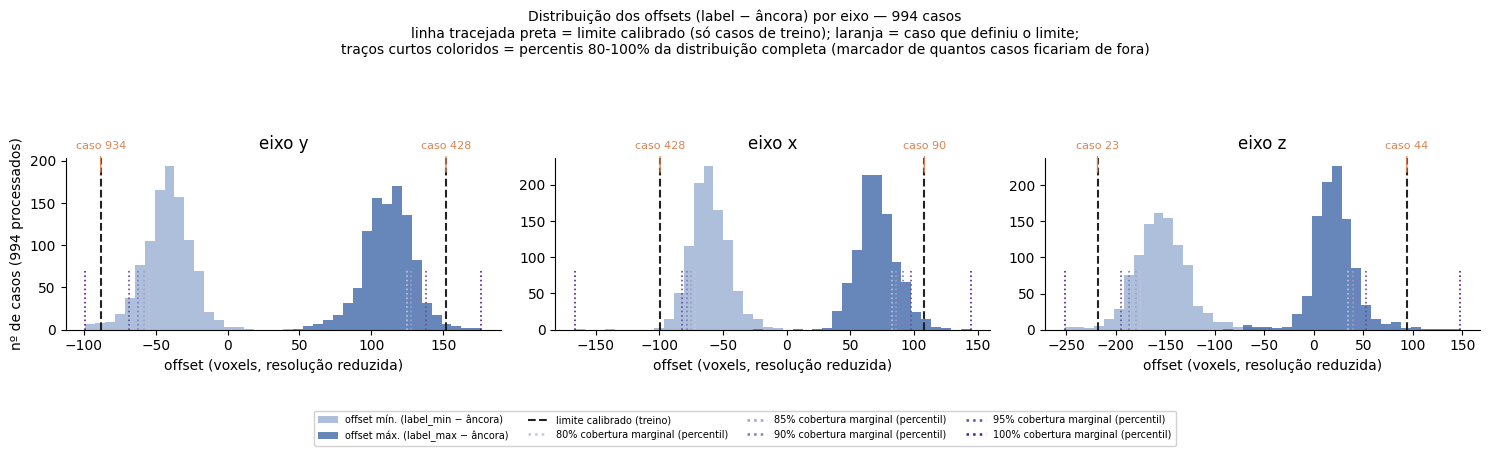

salvo: G:\DAC\heart-bounding-box\docs\img\step6v2_offset_histograms.png


In [4]:
plot_offset_histograms(ok, calibration)


## 2.1 Quantas imagens ficariam de fora, por nível de cobertura

Versão numérica dos traços de percentil do histograma acima: para cada eixo e lado (mínimo/máximo),
quantos dos 994 casos processados ficariam **fora** do bbox se o offset fosse calibrado num
percentil menos conservador que 100% (o mínimo/máximo absoluto, usado hoje). `compute_coverage_percentiles()`
vem de `plot_aorta_anchor_extremes.py` — mesma função usada para desenhar os traços do histograma.

Importante: isso é cobertura **marginal** (um eixo/lado por vez, sobre os 994 casos). A cobertura
**conjunta** (os 3 eixos simultaneamente, sobre casos fora da calibração) é sempre menor ou igual a
qualquer uma destas frações — é o que `coverage_val_*.csv`/`coverage_test_*.csv` já medem para o
nível 100% (94,7-96,7%, Seção 3 abaixo).

In [5]:
percentile_summary = compute_coverage_percentiles(ok)

# Tabela compacta: linhas = eixo/lado, colunas = nível de cobertura, valores = casos excluídos.
excluded_pivot = percentile_summary.pivot(
    index=["eixo", "lado"], columns="cobertura_%", values="casos_excluidos"
)
excluded_pivot.columns = [f"{level}%" for level in excluded_pivot.columns]
print(f"Casos excluídos por eixo/lado, em cada nível de cobertura marginal ({len(ok)} casos processados):")
excluded_pivot


Casos excluídos por eixo/lado, em cada nível de cobertura marginal (994 casos processados):


80%  85%  90%  95%  100%
eixo lado                                              
x    máx (label_max - âncora)  199  149  100   50     0
     mín (label_min - âncora)  199  149  100   50     0
y    máx (label_max - âncora)  199  149  100   50     0
     mín (label_min - âncora)  199  149  100   50     0
z    máx (label_max - âncora)  199  149  100   50     0
     mín (label_min - âncora)  199  149  100   50     0

In [6]:
def _threshold_at(axis: str, side_prefix: str, level: int = 100) -> float:
    mask = (
        (percentile_summary["eixo"] == axis)
        & percentile_summary["lado"].str.startswith(side_prefix)
        & (percentile_summary["cobertura_%"] == level)
    )
    return float(percentile_summary.loc[mask, "offset_threshold"].iloc[0])


print("Onde o limite calibrado (88 casos de treino) cai frente ao extremo real (994 casos):\n")
for axis in ("y", "x", "z"):
    cal_min = calibration["offset_min_reduced"][axis]
    cal_max = calibration["offset_max_reduced"][axis]
    true_min = _threshold_at(axis, "mín")
    true_max = _threshold_at(axis, "máx")
    print(
        f"  eixo {axis}: calibrado=[{cal_min:.1f}, {cal_max:.1f}]  "
        f"extremo real (994 casos)=[{true_min:.1f}, {true_max:.1f}]  "
        f"(gap min={cal_min - true_min:+.1f}, gap max={true_max - cal_max:+.1f})"
    )

print()
print(
    "Os 88 casos de treino já subestimam o extremo real da população maior em todos os eixos "
    "(gap > 0 = o limite calibrado fica aquém do pior caso já visto nos 994 processados) — "
    "consistente com a falha de cobertura medida em val/test (44/906, Seção 3)."
)


Onde o limite calibrado (88 casos de treino) cai frente ao extremo real (994 casos):

  eixo y: calibrado=[-88.3, 152.0]  extremo real (994 casos)=[-98.9, 176.4]  (gap min=+10.7, gap max=+24.5)
  eixo x: calibrado=[-99.3, 108.0]  extremo real (994 casos)=[-166.1, 144.5]  (gap min=+66.8, gap max=+36.4)
  eixo z: calibrado=[-218.6, 94.0]  extremo real (994 casos)=[-251.9, 148.0]  (gap min=+33.4, gap max=+54.0)

Os 88 casos de treino já subestimam o extremo real da população maior em todos os eixos (gap > 0 = o limite calibrado fica aquém do pior caso já visto nos 994 processados) — consistente com a falha de cobertura medida em val/test (44/906, Seção 3).


## 3. Piores casos de cobertura (val + test, fora da calibração)

Os 20 casos que mais ultrapassam o bbox calibrado, e por qual eixo. Reaproveita
`plot_worst_coverage_cases()` (mesma função usada para gerar
`docs/img/step6v2_worst_coverage_cases.png`); retorna também o detalhe por caso em `excess_df`.

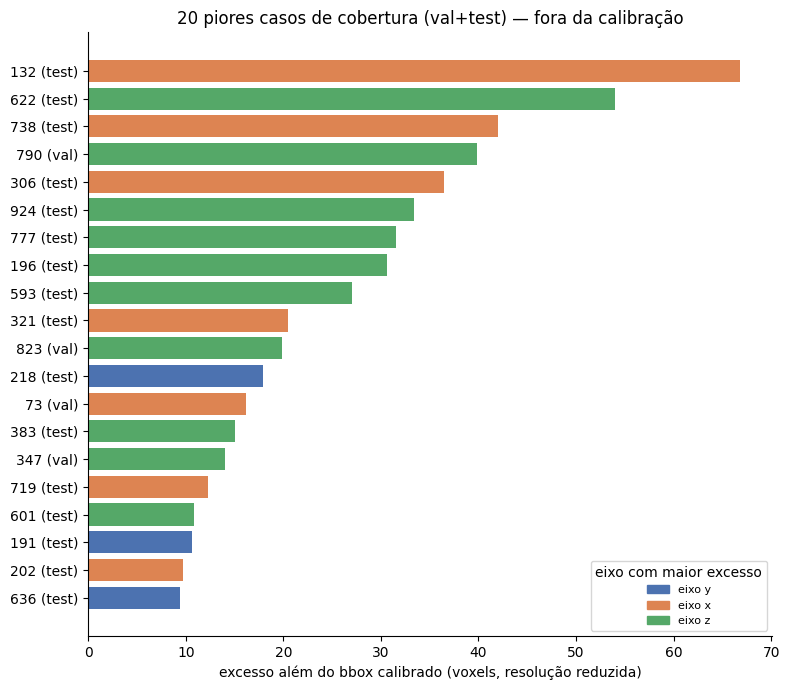

salvo: G:\DAC\heart-bounding-box\docs\img\step6v2_worst_coverage_cases.png
Falhas de cobertura — val: 7/210 (3.33%)
Falhas de cobertura — test: 37/696 (5.32%)


In [7]:
excess_df = plot_worst_coverage_cases(coverage, calibration)

num_val_fail = int((excess_df.loc[excess_df["split"] == "val", "max_excess"] > 0).sum())
num_test_fail = int((excess_df.loc[excess_df["split"] == "test", "max_excess"] > 0).sum())
print(f"Falhas de cobertura — val: {num_val_fail}/{len(val)} ({num_val_fail/len(val):.2%})")
print(f"Falhas de cobertura — test: {num_test_fail}/{len(test)} ({num_test_fail/len(test):.2%})")


## 4. `Rv` (redução volumétrica) com o bbox calibrado

Estimativa amostral (60 casos reais, seed fixa para reprodutibilidade) do `Rv = 1 − V_bbox/V_original`,
usando o espaçamento físico de cada caso (a extensão do bbox calibrado é fixa em voxels, mas o
espaçamento físico por paciente varia, então o `Rv` em si varia por caso).

In [8]:
extent_reduced = np.array([calibration["bbox_extent_reduced"][a] for a in ("y", "x", "z")])
downscale_factors = np.array(calibration["downscale_factors"])

random.seed(42)
sample_ids = random.sample(list(ok["img_id"]), 60)
dataset_root = REPO_ROOT / "dataset"
img_paths = {int(p.name.split(".")[0]): p for p in dataset_root.glob("*/*.img.nii.gz")}

# Cacheia spacing/shape (só o cabeçalho NIfTI, leitura rápida, sem carregar os voxels) por caso
# amostrado — reaproveitado na Seção 4.1 para recalcular Rv em outros níveis de percentil sem
# reabrir os arquivos nem rodar o lote de novo.
case_physical_info = {}
for img_id in sample_ids:
    nii_img, _ = load_raw_img_and_label(str(img_paths[img_id]))
    spacing = np.array(nii_img.header.get_zooms())
    orig_shape = np.array(nii_img.shape)
    case_physical_info[img_id] = {
        "spacing": spacing,
        "V_original": float(np.prod(orig_shape) * np.prod(spacing)),
    }


def rv_for_extent(extent_reduced_axes: np.ndarray) -> np.ndarray:
    """Rv por caso (amostra de 60 já cacheada) para uma extensão de bbox (y,x,z) em resolução reduzida."""
    values = []
    for info in case_physical_info.values():
        scaled_spacing = info["spacing"] * downscale_factors
        V_bbox = float(np.prod(extent_reduced_axes) * np.prod(scaled_spacing))
        values.append(1.0 - (V_bbox / info["V_original"]))
    return np.array(values)


rvs = rv_for_extent(extent_reduced)
print(f"Amostra: {len(rvs)} casos")
print(f"Rv médio:   {rvs.mean():.2%}")
print(f"Rv mediana: {np.median(rvs):.2%}")
print(f"Rv min-max: {rvs.min():.2%} a {rvs.max():.2%}")

bbox_extent_full = extent_reduced * downscale_factors
print()
print(f"Bbox calibrado em resolução integral (y,x,z): {tuple(bbox_extent_full.round(1))} voxels")
print("Imagens originais deste dataset costumam ter shape ~512x512x(200-300).")


Amostra: 60 casos
Rv médio:   5.01%
Rv mediana: 13.60%
Rv min-max: -15.34% a 13.60%

Bbox calibrado em resolução integral (y,x,z): (np.float64(480.5), np.float64(414.7), np.float64(312.6)) voxels
Imagens originais deste dataset costumam ter shape ~512x512x(200-300).


## 4.1 `Rv` e cobertura por nível de percentil

Recalibra o bbox usando um **percentil** do split de treino em vez do mínimo/máximo absoluto — para
cada nível de cobertura (80-100%), refaz exatamente o mesmo procedimento de
`calibrate_bbox_offsets` (offset mínimo/máximo por eixo, só que no percentil `100−nível`/`nível`
em vez de min/max), calcula `Rv` para a extensão resultante (reaproveitando `rv_for_extent()` e o
cache de spacing da Seção 4 — nenhum arquivo NIfTI extra é lido) e valida a cobertura **conjunta**
(os 3 eixos simultaneamente) nos 906 casos de val+test, exatamente como `validate_coverage()` faz
hoje só para o nível 100%.

Não precisa rodar `src/run_aorta_anchor.py` de novo — tudo vem de `all_cases.csv` +
`coverage_{val,test}_*.csv`, já carregados nesta sessão.

In [ ]:
def calibrate_at_level(train_df: pd.DataFrame, level: int) -> dict:
    """Recalibra offset_min/max por eixo no percentil `level`, a partir do split de treino.

    Generaliza `calibrate_bbox_offsets` (que usa min/max = percentil 100) para qualquer nível de
    cobertura desejado.
    """
    offset_min, offset_max = {}, {}
    for axis in ("y", "x", "z"):
        lo = train_df[f"label_{axis}_min"] - train_df[f"anchor_{axis}"]
        hi = train_df[f"label_{axis}_max"] - train_df[f"anchor_{axis}"]
        offset_min[axis] = float(np.percentile(lo, 100 - level))
        offset_max[axis] = float(np.percentile(hi, level))
    return {"offset_min": offset_min, "offset_max": offset_max}


def joint_coverage_rate(eval_df: pd.DataFrame, calib_at_level: dict) -> float:
    """Fração de casos de `eval_df` cobertos nos 3 eixos simultaneamente pelo bbox calibrado."""
    covered = np.ones(len(eval_df), dtype=bool)
    for axis in ("y", "x", "z"):
        bbox_min = eval_df[f"anchor_{axis}"] + calib_at_level["offset_min"][axis]
        bbox_max = eval_df[f"anchor_{axis}"] + calib_at_level["offset_max"][axis]
        axis_ok = (eval_df[f"label_{axis}_min"] >= bbox_min) & (eval_df[f"label_{axis}_max"] <= bbox_max)
        covered &= axis_ok.to_numpy()
    return float(covered.mean())


train_df = ok[ok["img_id"].isin(train_ids)]

level_rows = []
for level in COVERAGE_LEVELS:
    calib_at_level = calibrate_at_level(train_df, level)
    extent_reduced_level = np.array(
        [calib_at_level["offset_max"][a] - calib_at_level["offset_min"][a] for a in ("y", "x", "z")]
    )
    extent_full_level = extent_reduced_level * downscale_factors
    coverage_rate = joint_coverage_rate(coverage, calib_at_level)
    rv_level = rv_for_extent(extent_reduced_level)

    level_rows.append(
        {
            "cobertura_treino_%": level,
            #"extent_reduzido_y": round(extent_reduced_level[0], 1),
            #"extent_reduzido_x": round(extent_reduced_level[1], 1),
            #"extent_reduzido_z": round(extent_reduced_level[2], 1),
            #"extent_integral_y": round(extent_full_level[0], 1),
            #"extent_integral_x": round(extent_full_level[1], 1),
            #"extent_integral_z": round(extent_full_level[2], 1),
            "cobertura_fora_calibracao_%": round(coverage_rate * 100, 2),
            "rv_medio_%": round(rv_level.mean() * 100, 2),
            "rv_mediana_%": round(float(np.median(rv_level)) * 100, 2),
            "rv_min_%": round(rv_level.min() * 100, 2),
            "rv_max_%": round(rv_level.max() * 100, 2),
        }
    )

level_summary = pd.DataFrame(level_rows)
level_summary


,cobertura_treino_%,cobertura_fora_calibracao_%,rv_medio_%,rv_mediana_%,rv_min_%,rv_max_%
0,80,33.44,63.20,66.53,55.32,66.53
1,85,45.70,59.00,62.71,50.22,62.71
2,90,59.60,53.50,57.71,43.54,57.71
3,95,75.94,43.91,48.98,31.89,48.98
4,100,95.14,5.01,13.60,-15.34,13.60


## 5. Resumo dos achados até o momento (Capítulo 2 — pipeline de bounding box cardíaco)

**Etapas 1-4** (redução dimensional, threshold HU, maior componente conectado, empilhamento) —
implementadas e estáveis desde o início do capítulo. Produzem `lcc_image`/`lcc_mask`, usados como
entrada para todo o resto.

**Etapa 5** (centróide geométrico) — implementada e testada (`compute_geometric_centroid`).
Continua em uso, mas hoje aplicada à máscara da aorta, não mais ao `lcc_mask`.

**Etapa 6, 1ª tentativa — âncora pelo centróide do `lcc_mask`.** ❌ Achado bloqueante: o `lcc_mask`
isola o tronco inteiro (pele, parede torácica, mediastino), não o coração — não há fronteira de
densidade HU entre essas estruturas. 100% das fatias tocam a borda da imagem nos casos testados.
Substituída. Ver `docs/step6_envelope.md`.

**Etapa 6, 2ª tentativa — âncora pelo centróide da máscara da aorta** (Hough Circle Transform +
Level Set, código herdado do pipeline de segmentação arterial de Silva et al., reintroduzido só
para esse fim). O tamanho fixo do bbox é calibrado empiricamente: para cada eixo, o offset
mínimo/máximo observado entre os casos de treino, em relação à âncora. Determinístico (a âncora vem
de processamento de imagem, sem componente aprendido; os offsets são uma constante calculada uma
única vez via min/max sobre o treino).

- GPU local (RTX 4060) testada e **descartada**: acelera ~26%, mas troca o algoritmo de detecção de
  bordas (Canny → Sobel+percentil), mudando resultados, não só velocidade. Mantido `USE_GPU=false`.
- Lote completo (1000 imagens) rodado com o maior split de treino disponível (`train90`, 88 casos
  válidos) — decisão para reduzir o risco de calibrar com amostra pequena demais.
- **Resultado, e novo achado bloqueante**: cobertura em val/test **não chega a 100%** (~95-97%) e o
  `Rv` fica em torno de **5%** (às vezes negativo) — o bbox calibrado é quase do tamanho da imagem
  original. Causa: a agregação por mínimo/máximo é **independente por eixo**, então o bbox final
  precisa satisfazer o extremo de y de um paciente, o de x de outro, o de z de um terceiro — uma
  combinação que nenhum paciente real atinge sozinho, mas que o método produz mesmo assim. Mais
  casos de treino tende a piorar esse efeito, não corrigir.

**Isso ameaça a hipótese central do capítulo** (ganho simultâneo em qualidade *e* eficiência
computacional) — um `Rv` de ~5% não é redução de volume relevante.

**Decisão pendente**: como corrigir a calibração antes de implementar as etapas 7-9 (posicionamento,
corte, validação final com `Rv` oficial). Direções em discussão, não decididas — ver
`docs/step6v2_aorta_anchor.md`, seção "Possíveis direções":
1. Repensar a agregação (correlacionar eixos por paciente em vez de min/max independente).
2. Trocar a âncora para o ponto médio dos óstios coronarianos.
3. Investigar os casos mais extremos individualmente (outliers anatômicos vs. problema de label).
4. Reconsiderar se um bbox retangular de tamanho fixo é viável para este objetivo.